# 09. Models with covariates: group, sex, TMT set and inferred genotype

Three analyses on the gene-level table of the re-analysis:

1. **Main axis of variation.** What separates the donors most, and is it group, sex or batch?
2. **Group comparison with covariates.** Suicide versus control in a linear model with sex and TMT set, and in men only (all controls are men), with a permutation test.
3. **Protein-level consequences of inferred genotypes.** For the variants with a carrier pattern (notebook 08), is the abundance of the protein different in carriers, measured on peptides that do not contain the variant site?

The third analysis is the proteome-side counterpart of what MOSAIC-S will do with measured genotypes.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
RES = ROOT / "results"; TMTREP = ROOT / "results_large" / "search_ALL_SETS" / "tmt-report"
COL = {"control": "#2a78d6", "suicide": "#eb6834"}
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})

meta = pd.read_csv(RES / "sample_map.tsv", sep="\t")
samples = meta["sample"].tolist()
gene = pd.read_csv(TMTREP / "ratio_gene_MD.tsv", sep="\t").set_index("Index")
gene = gene[~gene["ProteinID"].str.split(";").apply(lambda ids: all(i.startswith("Cont_") for i in ids))]
Y = gene[samples].astype(float).dropna()
print(Y.shape[0], "genes quantified in all 36 donors")

def bh(p):
    p = np.asarray(p); o = np.argsort(p); q = np.empty_like(p)
    q[o] = np.minimum.accumulate((p[o] * len(p) / np.arange(1, len(p) + 1))[::-1])[::-1]
    return np.minimum(q, 1)

def ols(Y, X):
    """Row-wise ordinary least squares. Y: genes x donors, X: donors x terms. Returns coefficients, t and p per term."""
    XtX_inv = np.linalg.inv(X.T @ X)
    B = Y @ X @ XtX_inv
    resid = Y - B @ X.T
    df = X.shape[0] - np.linalg.matrix_rank(X)
    s2 = (resid ** 2).sum(axis=1) / df
    se = np.sqrt(np.outer(s2, np.diag(XtX_inv)))
    T = B / se
    return B, T, 2 * stats.t.sf(np.abs(T), df)

8384 genes quantified in all 36 donors


## 1. Main axis of variation

In [2]:
Z = Y.sub(Y.mean(axis=1), axis=0).to_numpy()
U, S, Vt = np.linalg.svd(Z, full_matrices=False)
var = S ** 2 / (S ** 2).sum()
pcs = pd.DataFrame(Vt[:5].T * S[:5], columns=[f"PC{i}" for i in range(1, 6)], index=samples)
meta = meta.join(pcs, on="sample")
is_s = (meta["group"] == "suicide").to_numpy(); is_f = (meta["sex"] == "F").to_numpy()
rows = []
for k in range(1, 6):
    v = meta[f"PC{k}"].to_numpy()
    p_group = stats.mannwhitneyu(v[is_s], v[~is_s]).pvalue
    p_group_men = stats.mannwhitneyu(v[is_s & ~is_f], v[~is_s & ~is_f]).pvalue
    p_sex = stats.mannwhitneyu(v[is_s & is_f], v[is_s & ~is_f]).pvalue          # sex within the suicide group
    p_set = stats.kruskal(*[v[(meta["tmt_set"] == s).to_numpy()] for s in range(1, 5)]).pvalue
    rows.append((f"PC{k}", round(100 * var[k - 1], 1), p_group, p_group_men, p_sex, p_set))
pca = pd.DataFrame(rows, columns=["component", "variance (%)", "p group", "p group (men only)", "p sex (within suicide)", "p TMT set"])
pca.to_csv(RES / "pca_associations.tsv", sep="\t", index=False)
pca.assign(**{c: pca[c].map("{:.2g}".format) for c in pca.columns[2:]})

,component,variance (%),p group,p group (men only),p sex (within suicide),p TMT set
0,PC1,15.2,8.7e-06,0.0001,0.88,0.044
1,PC2,12.8,0.37,1,0.41,2.7e-05
2,PC3,9.5,0.29,0.25,1,0.00012
3,PC4,8.2,0.69,0.6,1,3.8e-06
4,PC5,7.0,0.16,0.12,0.41,0.6


## 2. Suicide versus control with covariates

In [3]:
set_d = np.column_stack([(meta["tmt_set"] == s).to_numpy(float) for s in (2, 3, 4)])
Yv = Y.to_numpy()
# (a) all donors: group + sex + TMT set (the sex term is estimated within the suicide group)
Xa = np.column_stack([np.ones(36), is_s.astype(float), is_f.astype(float), set_d])
Ba, Ta, Pa = ols(Yv, Xa)
# (b) men only: group + TMT set
men = ~is_f
Xb = np.column_stack([np.ones(men.sum()), is_s[men].astype(float), set_d[men]])
Bb, Tb, Pb = ols(Yv[:, men], Xb)
# (c) unadjusted Welch test, all donors
Pc = stats.ttest_ind(Yv[:, is_s], Yv[:, ~is_s], axis=1, equal_var=False).pvalue

res = pd.DataFrame({"log2FC_all_adjusted": Ba[:, 1], "p_all_adjusted": Pa[:, 1], "q_all_adjusted": bh(Pa[:, 1]),
                    "log2FC_men": Bb[:, 1], "p_men": Pb[:, 1], "q_men": bh(Pb[:, 1]),
                    "log2FC_sex": Ba[:, 2], "q_sex": bh(Pa[:, 2]), "p_unadjusted": Pc, "q_unadjusted": bh(Pc)}, index=Y.index)
res.to_csv(RES / "group_comparison_with_covariates.tsv", sep="\t")
summary = pd.DataFrame({
    "genes with q < 0.05": [(res["q_unadjusted"] < 0.05).sum(), (res["q_all_adjusted"] < 0.05).sum(), (res["q_men"] < 0.05).sum()],
    "of these |log2FC| > 0.2": [np.nan, ((res["q_all_adjusted"] < 0.05) & (res["log2FC_all_adjusted"].abs() > 0.2)).sum(), ((res["q_men"] < 0.05) & (res["log2FC_men"].abs() > 0.2)).sum()],
}, index=["unadjusted Welch test, all donors", "group + sex + TMT set, all donors", "group + TMT set, men only (11 vs 13)"])
print("agreement of the group effect, all donors (adjusted) vs men only: r = %.2f" % np.corrcoef(res["log2FC_all_adjusted"], res["log2FC_men"])[0, 1])
print("genes with a sex effect at q < 0.05:", int((res["q_sex"] < 0.05).sum()))
summary

agreement of the group effect, all donors (adjusted) vs men only: r = 1.00
genes with a sex effect at q < 0.05: 6


,genes with q < 0.05,of these |log2FC| > 0.2
"unadjusted Welch test, all donors",889,NaN
"group + sex + TMT set, all donors",559,223.0
"group + TMT set, men only (11 vs 13)",523,207.0


Because all controls are men, the group effect in the model with a sex term is estimated from the men alone; the two adjusted analyses therefore agree by construction. The women contribute only to the sex term, which is small (few genes at q < 0.05, Y-chromosome proteins among them).

### Permutation test (men only)

Group labels are shuffled within each TMT set, which keeps the batch structure, and the model is refitted.

In [4]:
rng = np.random.default_rng(7)
obs = int((res["q_men"] < 0.05).sum()); perm = []
sets_men = meta.loc[men, "tmt_set"].to_numpy(); lab = is_s[men].astype(float)
for _ in range(1000):
    l = lab.copy()
    for s in range(1, 5):
        idx = np.flatnonzero(sets_men == s); l[idx] = rng.permutation(l[idx])
    X = np.column_stack([np.ones(men.sum()), l, set_d[men]])
    perm.append(int((bh(ols(Yv[:, men], X)[2][:, 1]) < 0.05).sum()))
perm = np.array(perm)
print(f"observed: {obs} genes at q < 0.05; permutations: median {int(np.median(perm))}, 95th percentile {int(np.percentile(perm, 95))}, maximum {perm.max()}")
print(f"permutation p = {(1 + (perm >= obs).sum()) / (1 + len(perm)):.4f}")

observed: 523 genes at q < 0.05; permutations: median 0, 95th percentile 0, maximum 23
permutation p = 0.0010


## 3. Protein-level consequences of inferred genotypes

For each variant with a carrier pattern in all four TMT sets and an unambiguous mass shift, the abundance of its protein is recomputed from peptides that do **not** overlap the variant position (median across peptides), then compared between carriers and non-carriers in a model with TMT set and group.
Excluding the overlapping peptides matters: the reference peptide at the variant site is lower in carriers by construction.

In [5]:
pat = pd.read_csv(RES / "variant_carrier_patterns.tsv", sep="\t", keep_default_na=False)
pat = pat[(pat["carrier_pattern"].astype(str) == "True") & (pat["mass_ambiguity"] == "") & (pat["n_sets"] == 4)]
calls = pd.read_csv(RES / "variant_carrier_calls.tsv", sep="\t")
pep = pd.read_csv(TMTREP / "ratio_peptide_MD.tsv", sep="\t", low_memory=False, usecols=["Gene", "ProteinID", "Peptide", "Start", "End"] + samples)
pep = pep[~pep["ProteinID"].astype(str).str.contains("_")]                     # peptides assigned to reference proteins only
rows = []
for v in pat.itertuples():
    c = calls[calls["entry"] == v.entry].set_index("sample")["carrier"].reindex(samples)
    if c.isna().any() or c.sum() < 3 or (~c.astype(bool)).sum() < 3:
        continue
    x = pep[(pep["Gene"] == v.gene) & ~((pep["Start"] <= int(v.pos)) & (pep["End"] >= int(v.pos)))]
    x = x[x[samples].notna().all(axis=1)]
    if len(x) < 2:
        continue
    y = x[samples].astype(float).median().to_numpy()[None, :]
    X = np.column_stack([np.ones(36), c.to_numpy(float), is_s.astype(float), set_d])
    B, T, P = ols(y, X)
    rows.append((v.gene, f"{v.ref}{v.pos}{v.alt}", v.dbsnp, int(c.sum()), len(x), B[0, 1], P[0, 1]))
cis = pd.DataFrame(rows, columns=["gene", "variant", "dbSNP", "carriers", "peptides outside the site", "carriers - non-carriers (log2)", "p"])
cis["q"] = bh(cis["p"].to_numpy()); cis = cis.sort_values("p")
cis.to_csv(RES / "protein_level_by_inferred_genotype.tsv", sep="\t", index=False)
cis.round(4)

,gene,variant,dbSNP,carriers,peptides outside the site,carriers - non-carriers (log2),p,q
1,ALDH2,E504K,rs671,10,30,-0.8029,0.0000,0.0000
10,VPS13C,I1132V,rs3784635,17,69,-0.0779,0.0006,0.0032
0,CKAP4,A348T,rs3088113,29,32,0.0911,0.0008,0.0032
5,GSTP1,I105V,rs1695,17,11,-0.0574,0.0984,0.2953
2,PSMB4,I234T,rs4603,24,8,-0.0250,0.3185,0.7645
8,ESD,G190E,rs9778,27,10,-0.0465,0.4621,0.8830
4,NDUFB9,P146S,rs10195,12,9,0.0170,0.5295,0.8830
11,HLA-A,R138Q,-,18,10,-0.0438,0.5887,0.8830
6,TFRC,G142S,rs3817672,15,16,-0.0216,0.7056,0.8872
9,NANS,E68D,rs1058446,20,10,0.0087,0.8269,0.8872


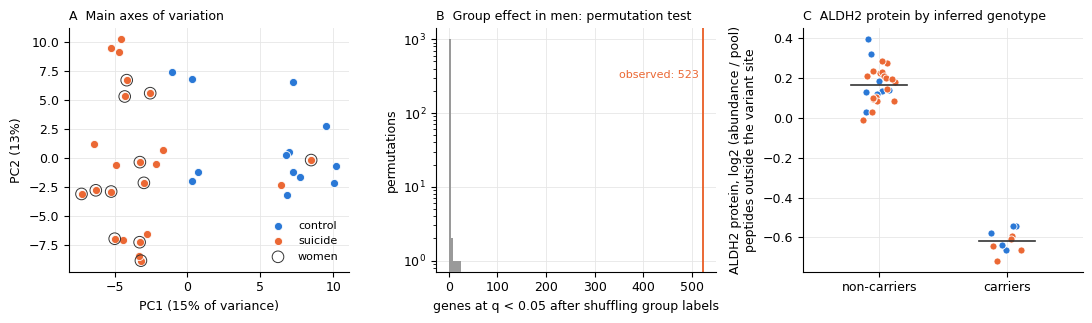

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(11, 3.3))
for g, sub in meta.groupby("group"):
    ax[0].scatter(sub["PC1"], sub["PC2"], s=34, color=COL[g], marker="o", edgecolor="white", linewidth=0.6, label=g, zorder=3)
fem = meta[meta["sex"] == "F"]
ax[0].scatter(fem["PC1"], fem["PC2"], s=70, facecolor="none", edgecolor="#333333", linewidth=0.7, zorder=4, label="women")
ax[0].set_xlabel(f"PC1 ({100 * var[0]:.0f}% of variance)"); ax[0].set_ylabel(f"PC2 ({100 * var[1]:.0f}%)")
ax[0].set_title("A  Main axes of variation", fontsize=9, loc="left"); ax[0].legend(frameon=False, fontsize=8)
ax[1].hist(perm, bins=np.arange(-0.5, max(perm.max(), 30) + 5, 5), color="#9a9a9a", zorder=3)
ax[1].set_yscale("log")
ax[1].axvline(obs, color="#eb6834", lw=1.4); ax[1].text(obs - 8, 300, f"observed: {obs}", color="#eb6834", ha="right", fontsize=8)
ax[1].set_xlabel("genes at q < 0.05 after shuffling group labels"); ax[1].set_ylabel("permutations")
ax[1].set_title("B  Group effect in men: permutation test", fontsize=9, loc="left")
top = cis.iloc[0]
c = calls[calls["gene"] == top["gene"]].drop_duplicates("sample").set_index("sample")["carrier"].reindex(samples).to_numpy(bool)
x = pep[(pep["Gene"] == top["gene"])]; pos = int("".join(ch for ch in top["variant"] if ch.isdigit()))
x = x[~((x["Start"] <= pos) & (x["End"] >= pos))]; x = x[x[samples].notna().all(axis=1)]
y = x[samples].astype(float).median().to_numpy(); rng2 = np.random.default_rng(3)
for i, (name, sel) in enumerate([("non-carriers", ~c), ("carriers", c)]):
    for gname, gsel in [("control", ~is_s), ("suicide", is_s)]:
        vv = y[sel & gsel]
        ax[2].scatter(i + rng2.uniform(-0.13, 0.13, len(vv)), vv, s=26, color=COL[gname], edgecolor="white", linewidth=0.6, zorder=3)
    ax[2].plot([i - 0.22, i + 0.22], [y[sel].mean()] * 2, color="#333333", lw=1.2, zorder=4)
ax[2].set_xticks([0, 1]); ax[2].set_xticklabels(["non-carriers", "carriers"]); ax[2].set_xlim(-0.6, 1.6)
ax[2].set_ylabel(f"{top['gene']} protein, log2 (abundance / pool)\npeptides outside the variant site")
ax[2].set_title(f"C  {top['gene']} protein by inferred genotype", fontsize=9, loc="left")
for a in ax:
    a.grid(color="#e6e6e6", lw=0.6); a.set_axisbelow(True)
fig.tight_layout(); fig.savefig(RES / "fig_models_with_covariates.png", dpi=300); plt.show()

## Conclusions

- The first principal component separates suicide from control, in all donors and in men alone, and is unrelated to sex. The next three components follow the TMT set, so the batch must be in the model.
- With TMT set (and sex) in the model, several hundred genes differ between the groups; the permutation test shows that this number cannot be produced by chance within this design. The data cannot say **why** the groups differ: the cohort description points to differences in the circumstances of death (most suicide cases died by drowning), and the publication provides no per-donor cause of death.
- Inferred genotype has a measurable consequence at the protein level for *ALDH2*: carriers of ALDH2\*2 have a clearly lower level of the protein on peptides that do not contain the variant site, as expected for a destabilising variant. For the other variants the effects are small or absent.

The third analysis is a cis protein-QTL test with genotypes read from the proteome itself. With sequenced genomes the same model applies to every variant of every donor, and extends to haplotypes and to effects across brain regions.